# Spatial GRN Integration of the Dentate Gyrus

## Tutorial 1: Spatial Imputation Using Tangram

**Author:** Xuan Cao  
**Affiliation:** Icahn School of Medicine at Mount Sinai  
**Email:** xuan.cao@mssm.edu  

**Contributors:** Donghoon Lee, Panos Roussos  

**Date:** March 20, 2026  

---

### Overview
This notebook demonstrates a pipeline for spatial imputation and integration of gene regulatory networks (GRNs) in the dentate gyrus. Using Tangram, we map single-cell transcriptomic profiles onto spatial transcriptomics data to enable downstream GRN inference in a spatially resolved context.

### Contents
1. Data loading  
2. Preprocessing  
3. Spatial mapping with Tangram  
4. Visualize marker genes
5. Imputation Performance  

# Imports

In [39]:
import scanpy as sc
import os
from pathlib import Path
import glob
import pandas as pd
import time
import numpy as np

# Inital setting for plot size
from matplotlib import rcParams,rc_context
import matplotlib.pyplot as plt
import seaborn as sns

import tangram as tg

import warnings
warnings.filterwarnings('ignore')

In [20]:
save_dir = 'SpatialGRN/01.tangram_align'
if not os.path.exists(save_dir):os.makedirs(save_dir)
os.chdir(save_dir)

# 1. Data loading

## 1.1 Load spatial data (Xenium)

### What is Xenium?

**10x Genomics Xenium** is an *in situ* spatial transcriptomics platform that measures the expression of a targeted gene panel (here ~366 genes) at single-cell resolution while preserving tissue morphology.  
The spatial coordinates for each cell are stored in `obsm['spatial']`, enabling direct mapping between gene expression and physical location within the tissue.

After loading, examine the AnnData summary to verify the expected dimensions and available annotations (`class`, `subclass`, `subtype`).

In [3]:
path_sp = 'data/human_DG_xenium.h5ad'
ad_sp = sc.read_h5ad(path_sp)
ad_sp

AnnData object with n_obs × n_vars = 44997 × 366
    obs: 'class', 'subclass', 'subtype'
    uns: 'subclass_colors'
    obsm: 'spatial'
    layers: 'counts', 'logCPM'

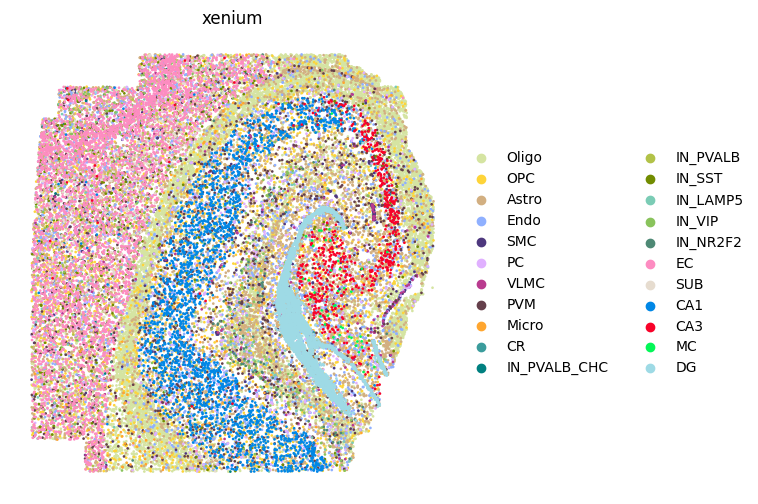

In [6]:
pal_subclass = {
    'DG': '#9edae5','MC': '#03F757','CA3': '#F80229','CA1': '#0087e6','SUB': '#e6dccf','EC': '#FD8CC1',
    'IN_NR2F2': '#4E8975','IN_VIP': '#89C35C','IN_LAMP5': '#7BCCB5','IN_SST': '#728C00','IN_PVALB': '#B2C248',
    'IN_PVALB_CHC': '#008080','CR': '#3B9C9C','Micro': '#FFA62F','PVM': '#65404b','VLMC': '#B93B8F',
    'PC': '#E0B0FF','SMC': '#4E387E','Endo': '#8FB0FF','Astro': '#D2AF81','OPC': '#FED439','Oligo': '#D5E4A2'
}

with plt.rc_context({"figure.figsize": (6, 6)}):
    sc.pl.spatial(
        ad_sp,
        color='subclass',
        size=6,
        spot_size=10,
        vmax = 150,
        frameon=False,
        title='xenium',
        palette=pal_subclass        
    )

## 1.2 Load snRNA

### Role of the snRNA-seq Reference

The snRNA-seq dataset acts as a **reference transcriptome**. It provides deep, genome-wide expression profiles with reliably annotated cell types.  
Tangram will learn a mapping from this reference to the spatially-resolved Xenium data, then *project* the full transcriptome onto each spatial location — effectively imputing thousands of genes that were not directly measured by the Xenium panel.

In [7]:
path_sc = 'data/human_DG_snrna.h5ad'
ad_sc = sc.read_h5ad(path_sc)
ad_sc

AnnData object with n_obs × n_vars = 9856 × 36601
    obs: 'class', 'subclass', 'subtype'
    layers: 'counts', 'logCPM'

# 2. Preprocessing

### Why Preprocessing?

Before mapping, we need to:
1. **Identify training genes** — the intersection of genes present in both snRNA and Xenium datasets. These shared genes anchor the alignment.
2. **Prepare AnnData objects** via `tg.pp_adatas()`, which computes cell-density priors and aligns gene ordering between the two objects.
3. **Set `.X` to raw counts** — Tangram works on un-normalised count data internally.

In [10]:
# Get cross validation genes and trainging genes
genes_sp = ad_sp.var_names.to_list()
genes_sc = ad_sc.var_names.to_list()
genes_train = [x for x in genes_sp if x in genes_sc]

print('Number of training genes: ' + str(len(genes_train)))
print('Training genes')

    

Number of training genes: 366
Training genes


### `tg.pp_adatas()` — Prepare AnnData Objects for Tangram

This function:
- Subsets both objects to the shared training genes.
- Computes a **cell-density prior** from the spatial data, which guides the mapping to respect the observed spatial distribution of cell types.
- Ensures consistent gene ordering between the two datasets.

After this step, both objects are ready for the alignment optimisation.

In [15]:
tg.pp_adatas(ad_sc, ad_sp, genes=genes_train,gene_to_lowercase= False)
assert ad_sc.uns['training_genes'] == ad_sp.uns['training_genes']


INFO:root:365 training genes are saved in `uns``training_genes` of both single cell and spatial Anndatas.
INFO:root:365 overlapped genes are saved in `uns``overlap_genes` of both single cell and spatial Anndatas.
INFO:root:uniform based density prior is calculated and saved in `obs``uniform_density` of the spatial Anndata.
INFO:root:rna count based density prior is calculated and saved in `obs``rna_count_based_density` of the spatial Anndata.


### Set Expression Matrix to Raw Counts

Tangram expects **raw (un-normalised) counts** in `.X`.  
We swap in the `counts` layer for both objects. This is critical — using normalised values would distort the optimisation.

In [11]:
ad_sp.X = ad_sp.layers['counts'].copy()
ad_sc.X = ad_sc.layers['counts'].copy()

# 3. Spatial mapping with Tangram

## 3.1 Find alignment

### How Tangram Mapping Works

`tg.map_cells_to_space()` solves an optimisation problem: **find a soft assignment (mapping) of single cells to spatial locations** such that the predicted spatial expression (aggregated from mapped single cells) best matches the observed Xenium expression.

Key parameters:
- `mode='cells'` — map at single-cell resolution (alternatives: `clusters`, `constrained`).
- `num_epochs` — number of optimisation iterations (more epochs → better convergence, but longer runtime).
- `device='cuda:0'` — use GPU if available (`'cpu'` otherwise).

> **Runtime:** On a single GPU, mapping ~10 000 single cells to ~45 000 spatial locations typically takes 5–15 minutes.  
> On CPU, expect significantly longer (~1–2 hours).

In [17]:
necho = 100

print(time.strftime("%Y-%m-%d %H:%M:%S", time.localtime()), ': Start mapping cells!',sep="")
ad_map = tg.map_cells_to_space(
    ad_sc, 
    ad_sp,
    mode="cells",
    num_epochs=necho,
    # device="cuda:0",
    device='cpu',
)
print(time.strftime("%Y-%m-%d %H:%M:%S", time.localtime()), ': Done mapping cells!',sep="")


INFO:root:Allocate tensors for mapping.
INFO:root:Begin training with 365 genes and rna_count_based density_prior in cells mode...


2026-03-20 21:46:27: Start mapping cells!


INFO:root:Printing scores every 100 epochs.


Score: 0.255, KL reg: 0.196


INFO:root:Saving results..


2026-03-20 22:07:00: Done mapping cells!


In [21]:
### Save ad_map files
f = save_dir + os.sep + "ad_map.h5ad"
ad_map.write_h5ad(filename =f, compression='gzip')

## 3.2 New whole transcriptomic spatial data via aligned single cells

### Projecting the Full Transcriptome

`tg.project_genes()` uses the learned mapping matrix to **impute expression for all genes** in the snRNA reference — not just the training genes.  
This gives us a new AnnData object (`ad_ge_sp`) with spatial coordinates and **whole-transcriptome** expression estimates, effectively upgrading the Xenium data from ~366 genes to ~36 000+ genes.

In [22]:
print(time.strftime("%Y-%m-%d %H:%M:%S", time.localtime()), ': Start impute for spatial!',sep="")
ad_ge_sp = tg.project_genes(adata_map=ad_map, adata_sc=ad_sc)
print('ad_ge_sp')
print(ad_ge_sp)
ad_ge_sp.obsm['spatial']= ad_sp.obsm['spatial']
print(time.strftime("%Y-%m-%d %H:%M:%S", time.localtime()), ': Done impute for spatial!',sep="")

2026-03-20 22:10:21: Start impute for spatial!
ad_ge_sp
AnnData object with n_obs × n_vars = 44997 × 30345
    obs: 'class', 'subclass', 'subtype', 'uniform_density', 'rna_count_based_density'
    var: 'n_cells', 'sparsity', 'is_training'
    uns: 'training_genes', 'overlap_genes'
2026-03-20 22:15:13: Done impute for spatial!


## 3.3 correct the gene names from lower case to upper case

### Correcting Gene Names

A known quirk of Tangram: it converts gene names to **lowercase** internally.  
We restore the original casing by mapping back to the snRNA reference gene names. This ensures compatibility with downstream databases and pathway tools.

In [24]:
### correct the gene names from lower case to upper case
## align the gene names
ad_sc_new = sc.read_h5ad(path_sc) # should reload the spatial data, because ad_sp gene name changed by tangram
genes_imputed = ad_ge_sp.var_names.to_list()
genes_measured = ad_sc_new.var_names.to_list()
aligned = [(a, b) for a in genes_imputed for b in genes_measured if a.lower() == b.lower()]
aligned = pd.DataFrame(aligned,columns=['imputed','measured'])
aligned[aligned['imputed'] != aligned['measured']]
ad_ge_sp.var_names = aligned['measured'].to_list()


In [28]:
### Save ad_ge_sp files
f = save_dir + os.sep + "ad_ge_sp.h5ad"
ad_ge_sp.write_h5ad(filename =f, compression='gzip')

# 4. Visualize marker genes

### Choosing Marker Genes

We visualise a curated set of **cell-type marker genes** on the spatial map to qualitatively assess imputation quality.  
Good imputation should show that:
- Known markers are enriched in the expected spatial regions (e.g., `PROX1` in the dentate gyrus granule cell layer).
- Spatial patterns are smooth and biologically plausible, not noisy or random.

Visualize selected marker genes to examine their spatial expression patterns
across cell types or regions.

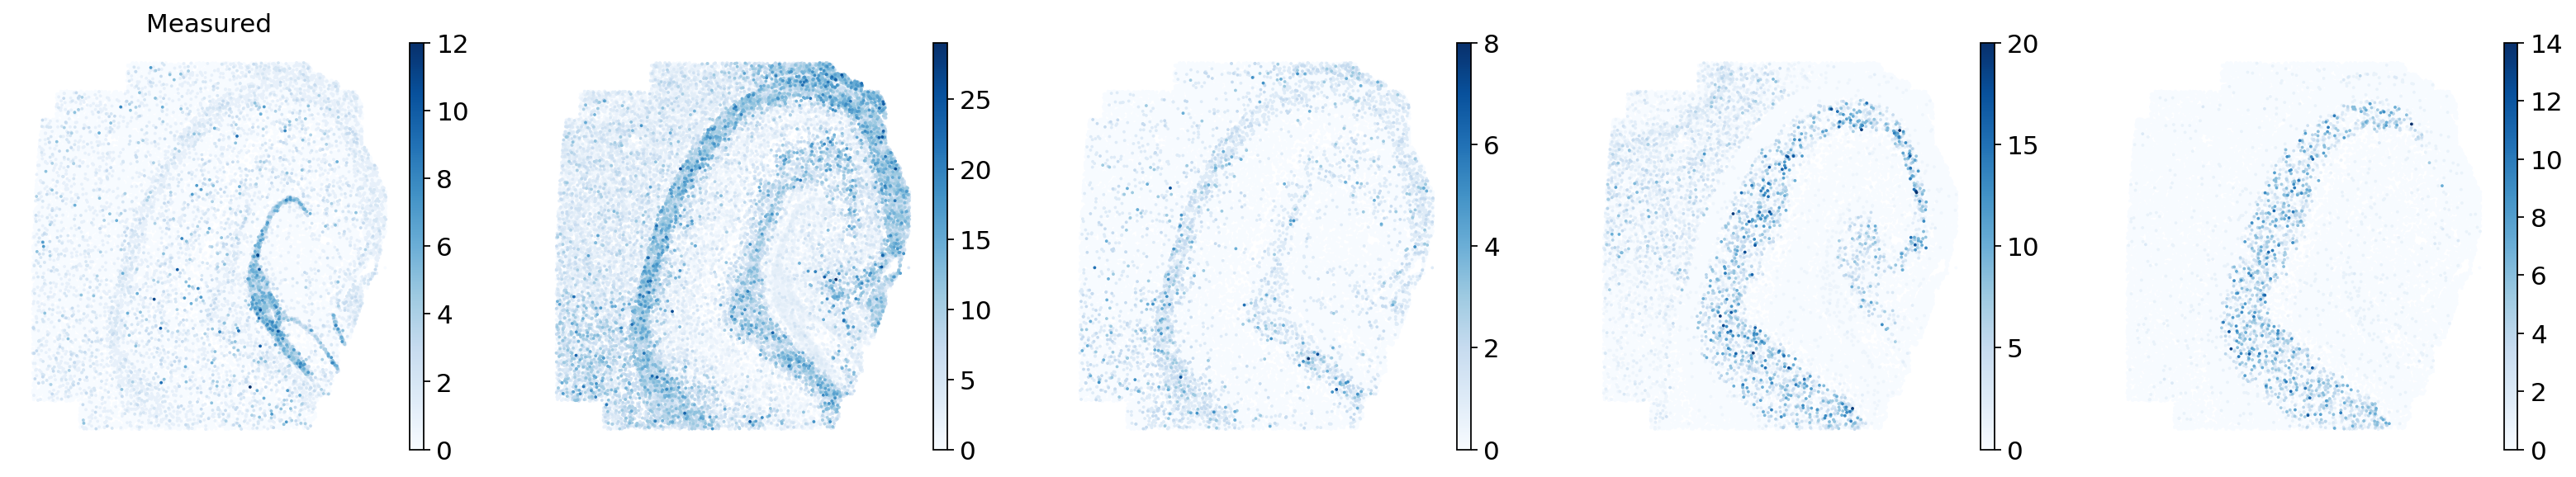

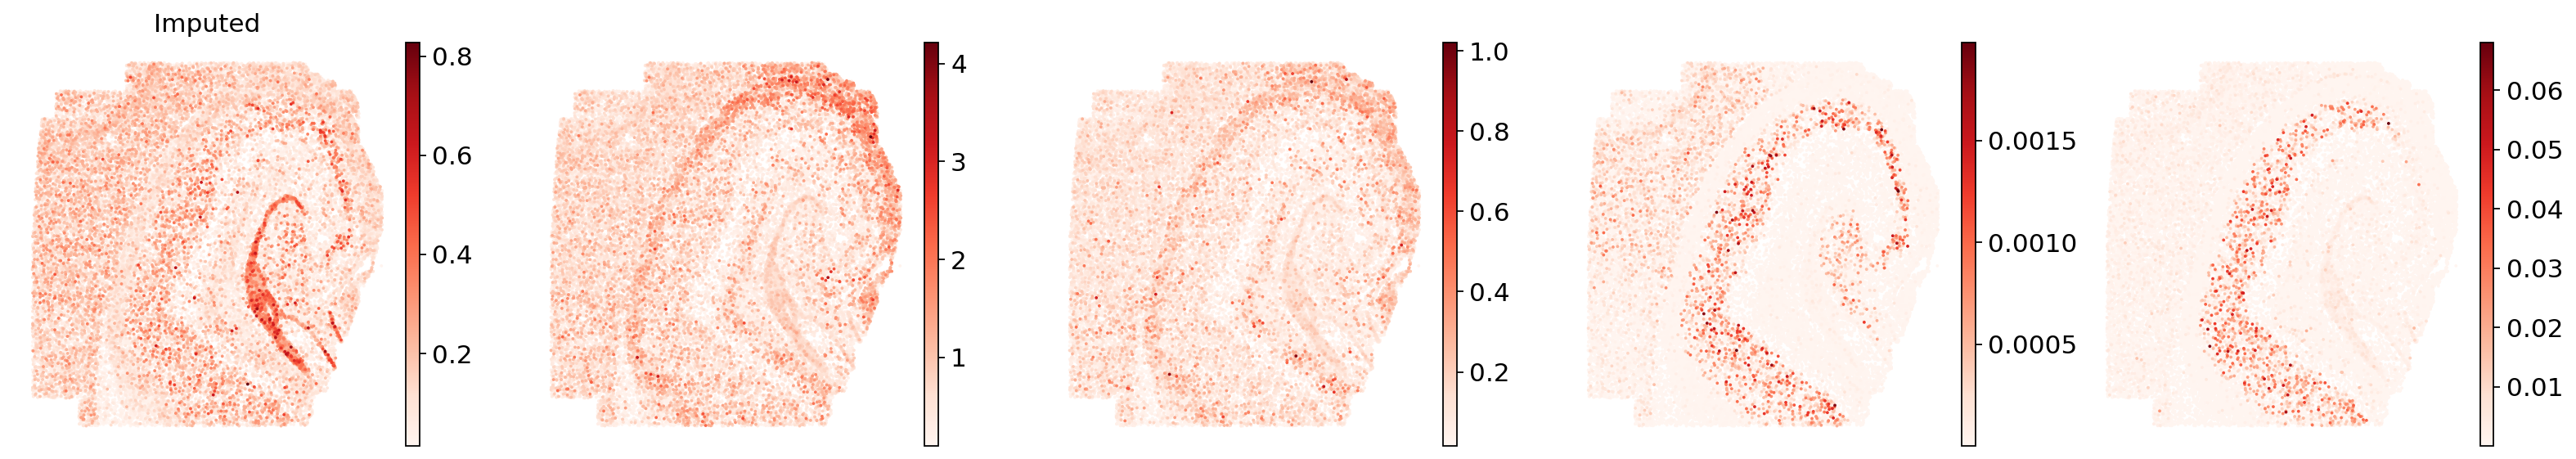

In [34]:
genes = ['PROX1','MBP','MOG','NEUROD6','FNDC1']

sc.set_figure_params(scanpy=True, fontsize=14, figsize=(4,4))

# Plot measured expression
sc.pl.spatial(ad_sp,color=genes,size=10,spot_size=8,frameon=False,cmap='Blues',ncols=5,wspace=0.2,title=['Measured'] + [''] * (len(genes) - 1))


# Plot tangram imputed expression
sc.pl.spatial(ad_ge_sp,color=genes,size=10,spot_size=8,frameon=False,cmap='Reds',ncols=5,wspace=0.2,title=['Imputed'] + [''] * (len(genes) - 1))



# 5. Imputation Performance

### What is the Pearson Correlation Coefficient (PCC)?

To **quantitatively** evaluate imputation quality, we compute the **gene-wise Pearson correlation** between:
- **Measured** Xenium expression (ground truth for the ~366 panel genes), and
- **Imputed** expression from Tangram for the same genes.

A PCC close to **1.0** indicates excellent agreement. Genes with low PCC may be poorly imputed due to low expression, dropout, or biological variability.

Compute Pearson correlation coefficient (PCC) between measured and imputed gene expression
to evaluate imputation performance. Higher PCC indicates better agreement.

## 5.1 calculate pcc between xenium measured and tangram-imputed

### The `pcc_between_2adatas` Function

This helper function:
1. Finds **common genes** and **common barcodes** between two AnnData objects.
2. Extracts and densifies the expression matrices.
3. Computes column-wise (gene-wise) Pearson correlation using `pd.DataFrame.corrwith()`.

The result is a DataFrame with one PCC value per gene.

In [40]:
def pcc_between_2adatas(
    ad1,
    ad2
):
    # get the common genes
    genes1 = ad1.var_names
    genes2 = ad2.var_names
    common_genes = sorted(list(set(genes1) & set(genes2)))
    print(f'common_genes: {len(common_genes)}')
    
    # get the common barcodes
    barcodes1 = ad1.obs_names
    barcodes2 = ad2.obs_names
    common_barcodes = sorted(list(set(barcodes1) & set(barcodes2)))
    print(f'common_barcodes: {len(common_barcodes)}')
    
    # subset adata to common genes and common barcodes
    ad1 = ad1[common_barcodes, common_genes]
    ad2 = ad2[common_barcodes, common_genes]
    mat1 = ad1.X
    mat2 = ad2.X
    
    if not isinstance(mat1, np.ndarray):
        mat1 = mat1.toarray()
    if not isinstance(mat2, np.ndarray):
        mat2 = mat2.toarray()
        
    mat1 = pd.DataFrame(mat1, columns=common_genes)
    mat2 = pd.DataFrame(mat2, columns=common_genes)

    # calculate PCC
    pcc = mat1.corrwith(mat2)
    pcc = pd.DataFrame(pcc,columns=['pcc'])
    
    return(pcc)

# calculate pcc for xenium between measured and tangram-imputed for common genes
pcc_sp = pcc_between_2adatas(ad_sp, ad_ge_sp)

common_genes: 365
common_barcodes: 44997


In [42]:
pcc_sp.head()

,pcc
ABCC9,0.828774
ACTR3B,0.709295
ACVR1C,0.708209
ADAMTS12,0.935147
ADAMTS16,0.668742


In [65]:
### Save ad_ge_sp files
f = save_dir + os.sep + "pcc_sp.csv"
pcc_sp.to_csv(f)

## 5.2 Gene-wise PCC Distribution (Boxplot)

### Interpreting the PCC Distribution

The boxplot below summarises the **distribution of gene-wise PCC values** across all shared genes.  
- The **median** gives an overall sense of imputation quality.
- The **interquartile range** shows consistency across genes.
- Outliers at the low end highlight genes that may need special attention.

A median PCC > 0.5 is generally considered good for spatial imputation; values > 0.7 indicate excellent performance.

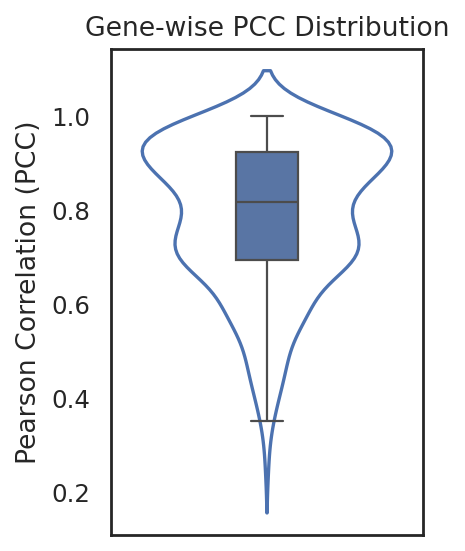

In [64]:
plt.figure(figsize=(2.5,4))
# violin
sns.violinplot(
    y=pcc_sp['pcc'],
    inner=None,
    color='#4C72B0',    
    fill=False
)

# box（叠加）
sns.boxplot(
    y=pcc_sp['pcc'],
    width=0.2,
    color='#4C72B0',
    showcaps=True,
    boxprops={'zorder': 2},
    showfliers=False
)

plt.ylabel('Pearson Correlation (PCC)')
plt.title('Gene-wise PCC Distribution')

plt.show()